In [40]:
%load_ext autoreload
%autoreload 2

import cv2
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [41]:
RESULTS_PATH = Path("../../results/collect/structure.parquet")
RESULTS = pd.read_parquet(RESULTS_PATH)
RESULTS

,top-1,top-5,top-10,frame-top-1,fold,frame_anonymization_method,frame_embedding_method,video_aggregation_method,video_embedding_method,identity_aggregation_method,pipeline
0,0.752306,0.865613,0.898551,0.625672,1,none,sface,none,None,none,frame
1,0.809122,0.891892,0.915541,0.666414,2,none,sface,none,None,none,frame
2,0.781885,0.870610,0.898336,0.654930,3,none,sface,none,None,none,frame
3,0.716733,0.836627,0.877470,0.626610,1,none,sface,none,None,pooling_mean,frame
4,0.766892,0.854730,0.881757,0.657236,2,none,sface,none,None,pooling_mean,frame
...,...,...,...,...,...,...,...,...,...,...,...
1759,0.045608,0.091216,0.141892,0.045608,2,pixelation,arcface,consensus_beta20,None,consensus_beta5,frame
1760,0.049908,0.103512,0.127542,0.049908,3,pixelation,arcface,consensus_beta20,None,consensus_beta5,frame
1761,0.048748,0.086957,0.110672,0.048748,1,pixelation,arcface,consensus_beta20,None,consensus_beta20,frame
1762,0.045608,0.092905,0.146959,0.045608,2,pixelation,arcface,consensus_beta20,None,consensus_beta20,frame


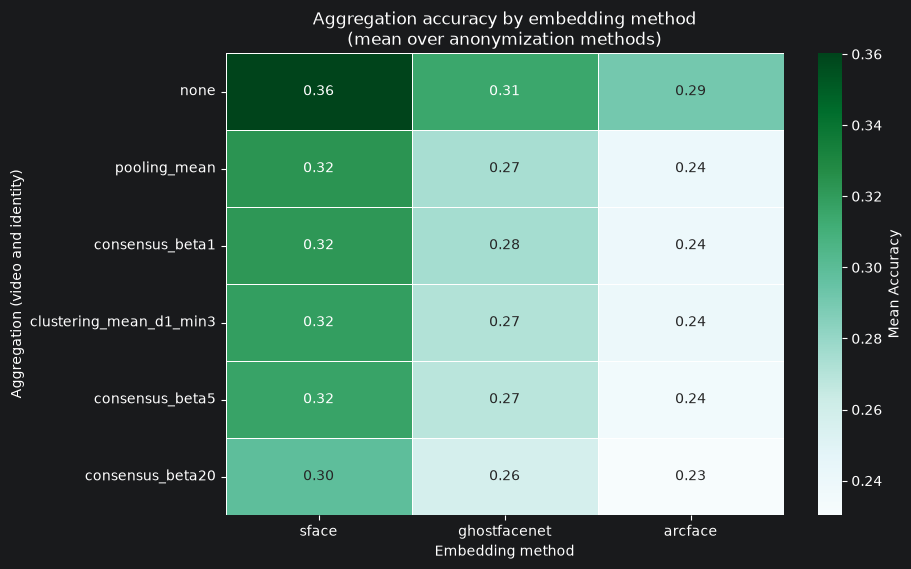

In [42]:
# Select all rows where the same aggregation method is used for both the video and identity. This collapses one dimension and simulates the previous results.
results = RESULTS[RESULTS["identity_aggregation_method"] == RESULTS["video_aggregation_method"]]

agg_order = (
    results.groupby("identity_aggregation_method")["top-1"].mean().sort_values(ascending=False).index
)
embedding_order = (
    results.groupby("frame_embedding_method")["top-1"].mean().sort_values(ascending=False).index
)

# Pivot `results`, not RESULTS: pivoting RESULTS averages over all nine video/identity
# combinations and silently undoes the filter above.
pivot_agg_embed = results.pivot_table(
    index="video_aggregation_method", columns="frame_embedding_method", values="top-1", aggfunc="mean"
).loc[agg_order, embedding_order]

plt.figure(figsize=(9, 6))
sns.heatmap(pivot_agg_embed, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Aggregation accuracy by embedding method\n(mean over anonymization methods)")
plt.xlabel("Embedding method")
plt.ylabel("Aggregation (video and identity)")
plt.show()

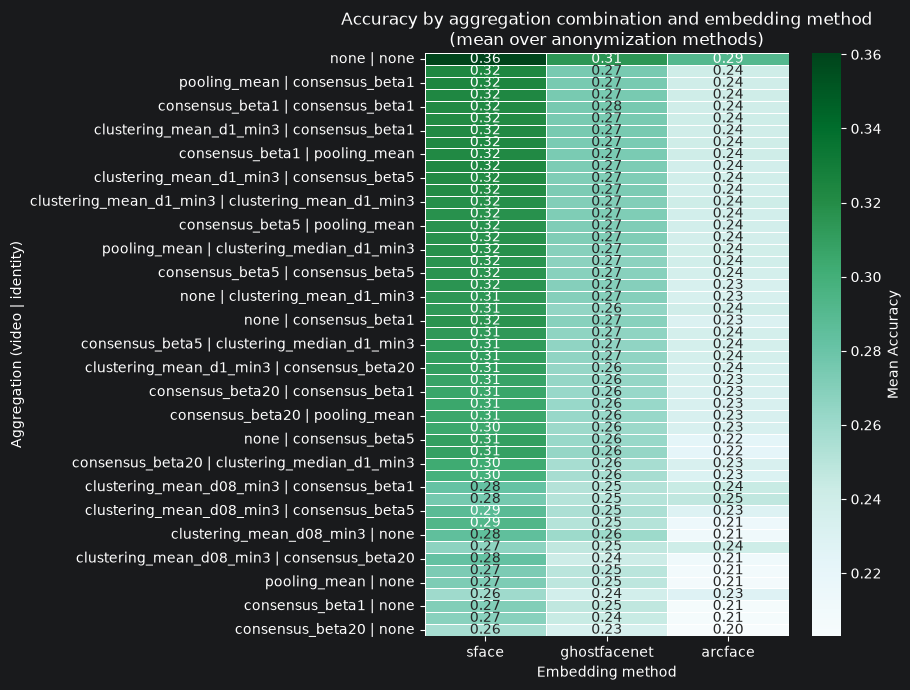

In [43]:
# Label every row with its full (video | identity) aggregation combination, so the mixed
# combinations stay visible instead of collapsing onto the matched ones.
#
# Derive from RESULTS, not from `results`: `results` is the matched-only subset built in the cell
# above (108 of 324 rows), so it only ever contains the three "X | X" combinations. That is what
# was dropping entries here.
combinations = RESULTS.assign(
    aggregation_method=RESULTS["video_aggregation_method"] + " | " + RESULTS["identity_aggregation_method"]
)

agg_order = (
    combinations.groupby("aggregation_method")["top-1"].mean().sort_values(ascending=False).index
)
embedding_order = (
    combinations.groupby("frame_embedding_method")["top-1"].mean().sort_values(ascending=False).index
)

pivot_agg_embed = combinations.pivot_table(
    index="aggregation_method", columns="frame_embedding_method", values="top-1", aggfunc="mean"
).loc[agg_order, embedding_order]

plt.figure(figsize=(9, 7))
sns.heatmap(pivot_agg_embed, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Accuracy by aggregation combination and embedding method\n(mean over anonymization methods)")
plt.xlabel("Embedding method")
plt.ylabel("Aggregation (video | identity)")
plt.tight_layout()
plt.show()

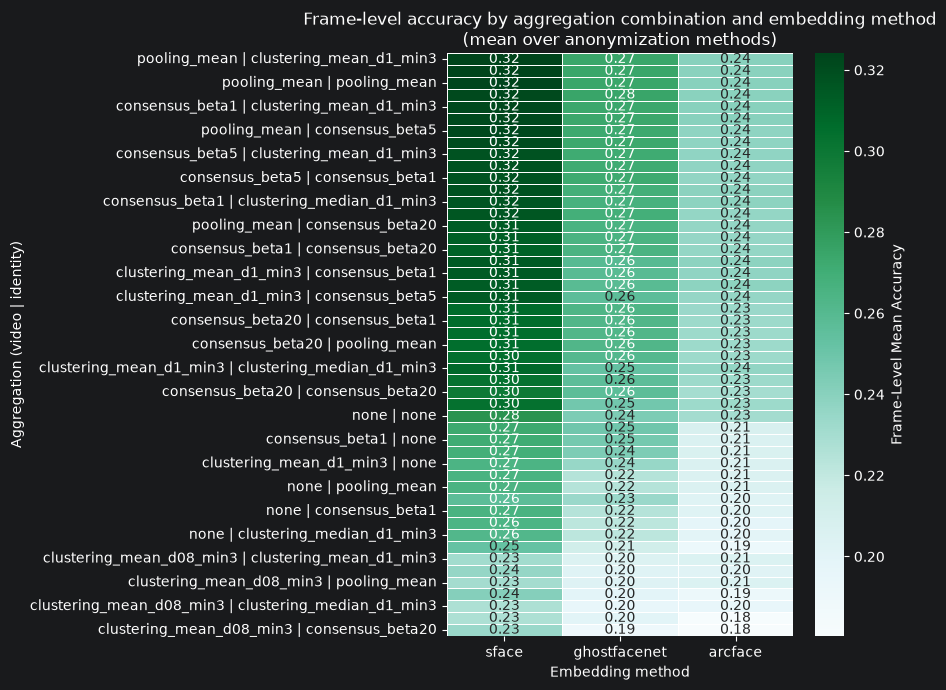

In [44]:
# Label every row with its full (video | identity) aggregation combination, so the mixed
# combinations stay visible instead of collapsing onto the matched ones.
#
# Derive from RESULTS, not from `results`: `results` is the matched-only subset built in the cell
# above (108 of 324 rows), so it only ever contains the three "X | X" combinations. That is what
# was dropping entries here.
combinations = RESULTS.assign(
    aggregation_method=RESULTS["video_aggregation_method"] + " | " + RESULTS["identity_aggregation_method"]
)

agg_order = (
    combinations.groupby("aggregation_method")["frame-top-1"].mean().sort_values(ascending=False).index
)
embedding_order = (
    combinations.groupby("frame_embedding_method")["frame-top-1"].mean().sort_values(ascending=False).index
)

pivot_agg_embed = combinations.pivot_table(
    index="aggregation_method", columns="frame_embedding_method", values="frame-top-1", aggfunc="mean"
).loc[agg_order, embedding_order]

plt.figure(figsize=(9, 7))
sns.heatmap(pivot_agg_embed, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Frame-Level Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Frame-level accuracy by aggregation combination and embedding method\n(mean over anonymization methods)")
plt.xlabel("Embedding method")
plt.ylabel("Aggregation (video | identity)")
plt.tight_layout()
plt.show()